In [1]:
import pandas as pd
import os.path as osp

full_metadata = pd.read_csv(r"C:\Users\peter\Repos\ENFIELD-PIML\sample_selection.csv")

In [2]:
full_metadata

,filepath,datestring,installation_ID,country,date,previous_days
0,Switzerland\15120\20200102.csv,20200102,15120,Switzerland,2020-01-02,0
1,Switzerland\15120\20200103.csv,20200103,15120,Switzerland,2020-01-03,1
2,Switzerland\15120\20200104.csv,20200104,15120,Switzerland,2020-01-04,2
3,Switzerland\15120\20200105.csv,20200105,15120,Switzerland,2020-01-05,3
4,Switzerland\15120\20200106.csv,20200106,15120,Switzerland,2020-01-06,4
...,...,...,...,...,...,...
3082651,Albania\61423\20230122.csv,20230122,61423,Albania,2023-01-22,6
3082652,Albania\61423\20230123.csv,20230123,61423,Albania,2023-01-23,7
3082653,Albania\61423\20230124.csv,20230124,61423,Albania,2023-01-24,8
3082654,Albania\61423\20230130.csv,20230130,61423,Albania,2023-01-30,0


In [3]:
full_metadata.country.unique()

<StringArray>
[  'Switzerland',        'Sweden',         'Spain',      'Slovenia',
      'Slovakia',       'Romania',      'Portugal',        'Poland',
        'Norway',       'Moldova',         'Malta',    'Luxembourg',
     'Lithuania', 'Liechtenstein',        'Latvia',         'Italy',
       'Ireland',       'Hungary',        'Greece',       'Germany',
        'France',       'Finland', 'Faroe_Islands',       'Estonia',
       'Denmark',       'Czechia',        'Cyprus',       'Croatia',
      'Bulgaria',       'Belgium',       'Austria',       'Albania']
Length: 32, dtype: str

In [4]:
metadata = pd.DataFrame()

for country in full_metadata.country.unique():
    country_metadata = pd.read_csv(osp.join(r'C:\Users\peter\Repos\ENFIELD-data\processed_unpack\nwp_0h', country, "metadata.csv"))
    metadata = pd.concat([metadata, country_metadata], ignore_index=True)

In [5]:
metadata = metadata[(metadata["Number of records 2020"] > 0) | (metadata["Number of records 2021"] > 0) | (metadata["Number of records 2022"] > 0) | (metadata["Number of records 2023"] > 0)]
metadata

,System ID,System Size (watts),Postcode / Zipcode,Panels,Panel Power (watts),Panel Brand,Inverters,Inverter Power (watts),Inverter Brand,Orientation,...,Import Peak Tariff,Import Off Peak Tariff,Import Shoulder Tariff,Import High Shoulder Tariff,Import Daily Charge,Elevation,Number of records 2020,Number of records 2021,Number of records 2022,Number of records 2023
0,77002,27600,NaN,92,300,?,1,20000,SE,EW,...,NaN,NaN,NaN,NaN,NaN,293.308899,163,356,302,295
1,37031,2200,NaN,8,275,Megasol,1,2500,SMA SB2500Hf-30,SW,...,NaN,NaN,NaN,NaN,NaN,522.111633,284,288,269,276
2,40229,8320,NaN,32,260,JAM6-60-260/SI,1,7200,Solaredge,EW,...,NaN,NaN,NaN,NaN,NaN,525.318298,332,355,296,292
3,85281,7200,NaN,40,180,3S Solar Plus Megaslate II,1,7400,Solar Edge SE7K-ER-01,S,...,NaN,NaN,NaN,NaN,NaN,554.645874,0,156,302,307
5,63316,6000,NaN,20,300,Sunage SAM 60/6,15,500,MT Micro E 500,SE,...,NaN,NaN,NaN,NaN,NaN,416.427399,332,347,294,225
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4320,20513,15300,NaN,60,255,LG,1,15000,SMA Tripower 15000TL,S,...,20.0,20.0,20.0,20.0,NaN,581.598022,331,32,0,0
4321,80174,5760,NaN,18,320,Maysun Solar,1,10000,Fronius,S,...,NaN,NaN,NaN,NaN,NaN,218.200119,35,362,301,307
4322,18396,490,NaN,2,245,Trina TSM-PC 05,1,480,Enecsys,W,...,NaN,NaN,NaN,NaN,NaN,298.046692,262,305,237,252
4323,57241,2640,NaN,11,240,Sanyo,1,3000,SMA SB300 TL20,SW,...,NaN,NaN,NaN,NaN,NaN,355.592377,102,295,279,55


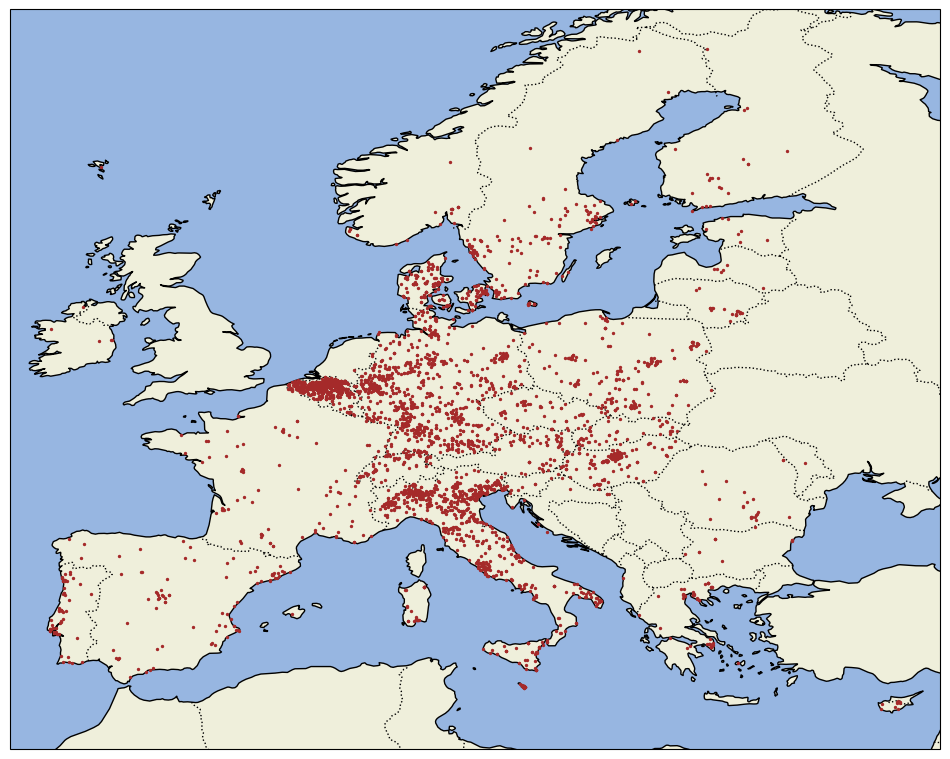

In [13]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Example lat/lon points (e.g. cities)
lats = metadata["Latitude"].tolist()
lons = metadata["Longitude"].tolist()

# Create figure with a map projection
fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set map extent to Europe
ax.set_extent([metadata["Longitude"].min() - 2, metadata["Longitude"].max() + 2, metadata["Latitude"].min() - 2, metadata["Latitude"].max() + 2], crs=ccrs.PlateCarree())

# Add features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)

# Scatter points (IMPORTANT: specify transform!)
ax.scatter(lons, lats,
           c='brown',
           s=2,
           transform=ccrs.PlateCarree(),
           zorder=5)

plt.savefig(r"installations.pdf", bbox_inches='tight')